## Problem statement

You work as a data analyst for a small **shared-bike operator**. Every night the vans collect the bikes that users leave around a district, and the operator wants to know **where people really park**: which areas are real parking zones and which bikes are simply left alone. The data has the position of **20 parked bikes** (two numbers per bike: how far east and how far north, both in **hundreds of metres**) and **no label**. This is **unsupervised learning**, and **DBSCAN** is the algorithm that defines a cluster as a *dense region* of points and leaves the isolated ones as **noise**. But DBSCAN has a catch: **you must choose two parameters, `eps` (the radius of the neighbourhood) and `min_samples` (how many points make a neighbourhood dense)**, and the data does not say them out loud.

In this exercise everything is already written and plotted for you: the 20 bikes, the DBSCAN algorithm built from scratch, the **k-distance plots** for several candidate values of `min_samples` and the **sweep of `eps`** (number of clusters and noise points as `eps` grows). **Your only job is to read those plots, decide which `EPS` and `MIN_SAMPLES` they support, and change the two variables of the exercise cell** (they start with values that do not work). Then you run the rest of the notebook and describe what you obtain. The teacher will comment on the best choice in class, after you have made your own decision.

What each section does:

- **0. Setup** — imports.
- **1. The parked bikes** — the 20 bikes (given).
- **2. Looking at the data** — a scatter plot with the index of every bike.
- **3. DBSCAN toolbox** — our own `dbscan` function and a plot helper (given).
- **4. k-distance plots** — one curve for each candidate `min_samples` (given).
- **5. Sweep of eps** — clusters and noise as `eps` grows (given).
- **6. Exercise: choose EPS and MIN_SAMPLES** — the only `TODO`.
- **7. Interpreting the result** — the final model with your values, core / border / noise.
- **8. Reflection** and **9. Conclusions**.

> **Decision / Why:** everything mechanical is given because the real skill of this practice is **reading evidence, deciding the parameters of a density-based algorithm and defending the decision**. The single cell you must complete starts with `# TODO`; the cells after it work with any value you write.

| Item | Detail |
|---|---|
| **Learning Outcomes** | **LO1** — In-depth knowledge of the concepts, requirements and principles of AI and Machine Learning (unsupervised learning, density-based clusters, noise, the role of the parameters). **LO3** — Detailed understanding of classical and modern AI techniques (DBSCAN and the criteria used to choose `eps` and `min_samples`). **LO4** — Competence in implementing AI solutions with appropriate languages and tools (reading and running Python, numpy, matplotlib and scikit-learn code). **LO5** — Critical evaluation of the limitations and ethical issues of AI (see the Reflection). |
| **SLR phase** | 2 — Immersion: "I understand how it works" |
| **Activity type** | **Business Case**. A Business Case means analysing and deciding on something that already happened and is documented: here the evidence (the k-distance plots and the sweep of `eps`) is already produced and you have to read it and take a reasoned decision. A Challenge would be generating your own solution to an open problem, and a Simulation would be acting inside an environment that imitates reality; this exercise is neither of them, because you do not build anything new: you analyse existing evidence and defend a decision. |
| **Deliverable** | This notebook with `EPS` and `MIN_SAMPLES` chosen, executed, with your written answers and the **Reflection** (section 8), uploaded to Blackboard. |
| **Environment** | Google Colab, with numpy, pandas, matplotlib and scikit-learn. No downloads are needed: the data is written inside the notebook. |

# 0. Setup

We import the libraries we need.

In [10]:
# If you run this in an environment without the libraries, uncomment the next line:
# %pip install numpy pandas matplotlib scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 4)

# 1. The parked bikes

The district has **20 parked bikes**. Each bike is a row with two numbers, `east` and `north`, both in **hundreds of metres**. Both columns use the **same unit**, so a distance means the same in east and in north and we do not need to scale anything.

In [11]:
X = np.array([[1.0, 1.0], [1.5, 1.7], [2.2, 2.0], [2.9, 2.4], [3.7, 2.5],
    [4.4, 2.1], [4.9, 1.5], [5.3, 0.8],
    [5.6, -0.3],
    [2.0, 1.4], [3.3, 1.7], [4.2, 1.4],
    [8.0, 5.0], [8.5, 5.4], [8.4, 4.5], [7.6, 5.5], [9.1, 5.0],
    [1.0, 6.5], [5.5, 8.5], [9.5, 1.0],
])

feature_names = ["east", "north"]
bikes = pd.DataFrame(X, columns=feature_names)
bikes.index.name = "bike"

print("Shape of X:", X.shape, "-> 20 bikes and 2 features")
bikes

Shape of X: (20, 2) -> 20 bikes and 2 features


,east,north
bike,,
0,1.0,1.0
1,1.5,1.7
2,2.2,2.0
3,2.9,2.4
4,3.7,2.5
5,4.4,2.1
6,4.9,1.5
7,5.3,0.8
8,5.6,-0.3


# 2. Looking at the data

Before running any algorithm, **look at the data**. Every bike is drawn with its index, so you can refer to it later.

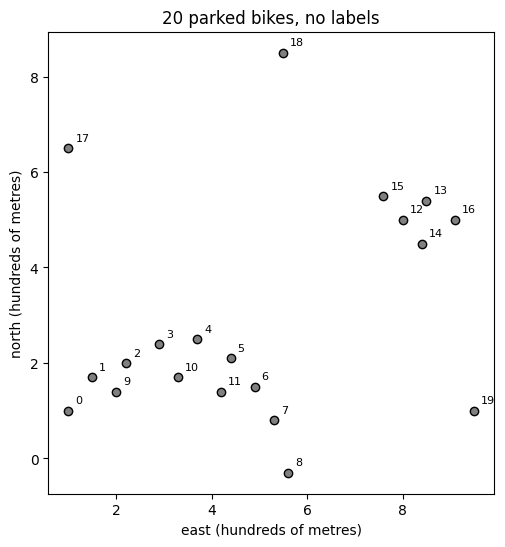

In [12]:
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c="gray", edgecolor="black")
for i, (x, y) in enumerate(X):
    plt.annotate(str(i), (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.xlabel("east (hundreds of metres)")
plt.ylabel("north (hundreds of metres)")
plt.title("20 parked bikes, no labels")
plt.gca().set_aspect("equal")
plt.show()

# 3. DBSCAN toolbox

These are the functions of the step-by-step practice, now all together:

- `distance_matrix`: Euclidean distance between every pair of bikes.
- `region_query`: the **eps-neighbourhood** of a bike, i.e. the bikes at distance `eps` or less (itself included).
- `find_core_points`: a bike is a **core** point if its neighbourhood has at least `min_samples` bikes.
- `expand_cluster`: starting from a core point, the cluster grows through the neighbourhoods of the core points it reaches. The non-core points reached are **border** points.
- `dbscan`: goes through the bikes in index order, starts a new cluster at every core point not yet assigned and leaves as **noise** (label `-1`) the bikes that no cluster reaches.

Nothing in this cell needs to be changed.

In [13]:
def distance_matrix(X):
    # matrix (n_points, n_points): Euclidean distance between every pair of points
    return np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)

def region_query(D, i, eps):
    # indices of the points whose distance to point i is at most eps (point i included)
    return np.where(D[i] <= eps)[0]

def find_core_points(neighbours, min_samples):
    # boolean mask: True where the neighbourhood has at least min_samples points
    return np.array([len(nb) >= min_samples for nb in neighbours])

def expand_cluster(start, cluster_id, labels, neighbours, core_mask):
    # Grows cluster `cluster_id` from the core point `start`. Modifies `labels` in place (-1 = no cluster yet).
    labels[start] = cluster_id
    seeds = [start]
    while seeds:
        p = seeds.pop()                       # take one seed
        if core_mask[p]:                      # only core points expand the cluster
            for q in neighbours[p]:
                if labels[q] == -1:           # not assigned to any cluster yet
                    labels[q] = cluster_id
                    seeds.append(q)

def dbscan(X, eps, min_samples):
    # DBSCAN from scratch. Returns labels (-1 = noise) and the indices of the core points
    D = distance_matrix(X)
    neighbours = [region_query(D, i, eps) for i in range(len(X))]
    core_mask = find_core_points(neighbours, min_samples)
    labels = np.full(len(X), -1)
    cluster_id = 0
    for i in range(len(X)):
        if labels[i] != -1 or not core_mask[i]:
            continue                          # already in a cluster, or not a core point
        expand_cluster(i, cluster_id, labels, neighbours, core_mask)
        cluster_id += 1
    return labels, np.where(core_mask)[0]

def plot_dbscan(X, labels, core_indices, title="", ax=None):
    # one colour per cluster; core points = circles, border points = squares, noise = grey crosses
    ax = ax if ax is not None else plt.gca()
    colors = np.array(["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:brown", "tab:pink", "tab:olive", "tab:cyan"])
    is_core = np.zeros(len(X), dtype=bool)
    is_core[core_indices] = True
    for cl in sorted(set(labels) - {-1}):
        sel = labels == cl
        ax.scatter(X[sel & is_core, 0], X[sel & is_core, 1], c=colors[cl % len(colors)], marker="o", s=40, edgecolor="black")
        ax.scatter(X[sel & ~is_core, 0], X[sel & ~is_core, 1], c=colors[cl % len(colors)], marker="s", s=40, edgecolor="black")
    ax.scatter(X[labels == -1, 0], X[labels == -1, 1], c="gray", marker="x", s=50)
    ax.set_title(title)
    ax.set_xlabel("east (hundreds of metres)")
    ax.set_ylabel("north (hundreds of metres)")
    ax.set_aspect("equal")

Is our implementation correct? We compare it with `DBSCAN` of scikit-learn on one arbitrary pair of values (only for this check): the core points, the noise and the grouping must be identical.

In [14]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

check_labels, check_core = dbscan(X, 1.0, 3)
check_sk = DBSCAN(eps=1.0, min_samples=3).fit(X)

same_pairs = lambda a, b: np.array_equal(a[:, None] == a[None, :], b[:, None] == b[None, :])
assert np.array_equal(np.sort(check_sk.core_sample_indices_), np.sort(check_core)), "Core points differ"
assert np.array_equal(check_sk.labels_ == -1, check_labels == -1), "Noise points differ"
assert same_pairs(check_sk.labels_, check_labels), "Groupings differ"
print("Same core points, same noise and same grouping as scikit-learn: our implementation is correct.")

Same core points, same noise and same grouping as scikit-learn: our implementation is correct.


# 4. k-distance plots

How do we choose `eps` without trying at random? The **k-distance plot** helps:

1. For every bike we compute the distance to its `k`-th nearest neighbour, where `k = min_samples` (the bike itself counts as the first neighbour, at distance 0, exactly as in the definition of core point).
2. We sort those distances from the smallest to the largest and plot them.

How to read each curve: the **low part** on the left contains the bikes whose `k`-th neighbour is close, the **rise** on the right contains the bikes in sparse places (the candidates to be noise), and the **knee (elbow)** between them is a reasonable range for `eps`.

The `min_samples` has its own rules of thumb: it should be **at least the number of dimensions + 1**, and a common choice is **2 times the number of dimensions**. A very small value makes DBSCAN too permissive and a very large value makes it too strict. Because of that we draw one curve for each of several candidate values of `min_samples`. With only 20 bikes, we do not go beyond 6.

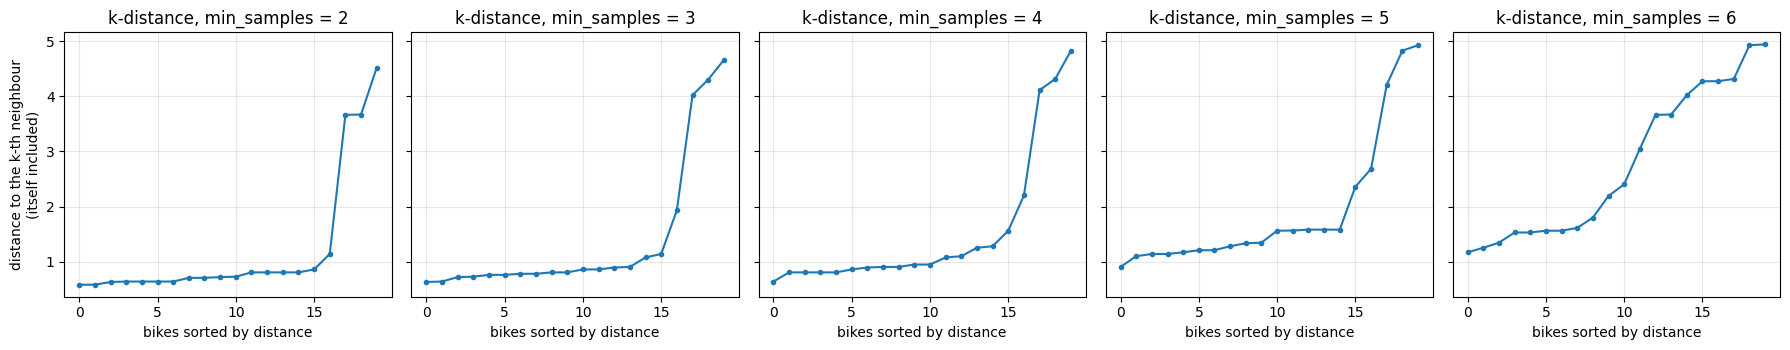

In [15]:
candidate_ms = [2, 3, 4, 5, 6]            # candidate values of min_samples (only to draw the plots)

fig, axes = plt.subplots(1, len(candidate_ms), figsize=(18, 3.6), sharey=True)
for ax, ms in zip(axes, candidate_ms):
    nn = NearestNeighbors(n_neighbors=ms).fit(X)
    dist, _ = nn.kneighbors(X)            # column 0 is the point itself (distance 0)
    k_dist = np.sort(dist[:, ms - 1])
    ax.plot(k_dist, marker="o", markersize=3)
    ax.set_title(f"k-distance, min_samples = {ms}")
    ax.set_xlabel("bikes sorted by distance")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("distance to the k-th neighbour\n(itself included)")
plt.tight_layout()
plt.show()

Look at the five curves: where is the knee in each of them? Does it stay at about the same height or does it move? Also notice the right end of the curves: those are the bikes that DBSCAN will probably call noise.

# 5. Exercise: choose EPS and MIN_SAMPLES

This is the only cell you have to change. It starts with two values that do not work. Look at the plots of sections 4 and 5 and **replace both numbers** with the ones the evidence supports. Then run the cell and everything after it.

In [ ]:
# TODO: look at the k-distance plots and the sweep of eps and replace the two values below
EPS = 0.01          # radius of the neighbourhood (hundreds of metres)
MIN_SAMPLES = 1    # minimum number of bikes (itself included) to be a core point


## Your answer

Justify your two values using **only** what you can see in the plots of sections 4 and 5 (double-click this cell and write below):

- Where is the knee of the k-distance curve for your `MIN_SAMPLES`, and why does your `EPS` fall in that range?
- How wide is the stable zone of the sweep around your `EPS`? Would the result change if `EPS` were a bit smaller or a bit larger?
- Why did you reject the other candidate values of `min_samples`?

*Your answer:* 

# 6. Interpreting the result

We run **our own `dbscan`** with your `EPS` and `MIN_SAMPLES`, count clusters and noise, and show the role of every bike: **core**, **border** or **noise**.

Clusters found: 2 | noise bikes: 3 of 20
core      15
noise      3
border     2


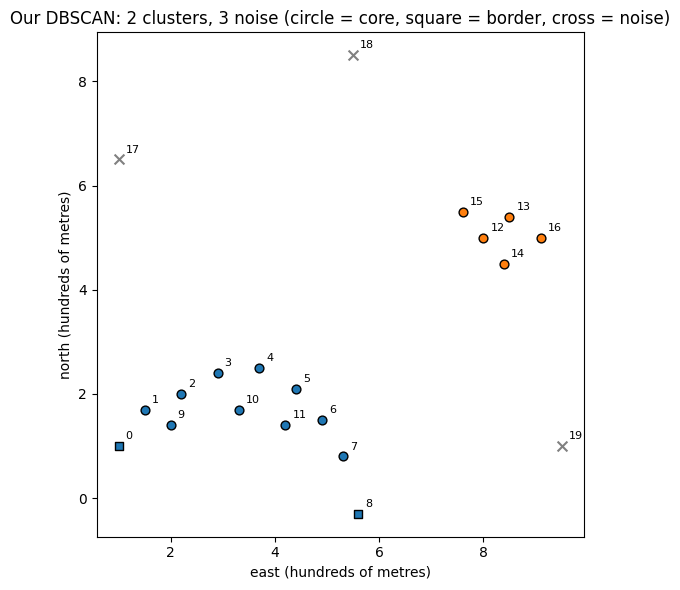

In [17]:
final_labels, final_core = dbscan(X, EPS, MIN_SAMPLES)

n_final = len(set(final_labels) - {-1})
n_noise = int(np.sum(final_labels == -1))
print(f"Clusters found: {n_final} | noise bikes: {n_noise} of {len(X)}")

roles = np.where(np.isin(np.arange(len(X)), final_core), "core", np.where(final_labels == -1, "noise", "border"))
print(pd.Series(roles).value_counts().to_string())

fig, ax1 = plt.subplots(figsize=(8, 6))
plot_dbscan(X, final_labels, final_core, f"Our DBSCAN: {n_final} clusters, {n_noise} noise (circle = core, square = border, cross = noise)", ax=ax1)
for i, (x, y) in enumerate(X):
    ax1.annotate(str(i), (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.tight_layout()
plt.show()

Read the plot: **circles** are core points (inside a dense area), **squares** are border points (they belong to a cluster but their own neighbourhood is not dense) and **crosses** are noise.

## Your answer

Describe what you obtained (double-click this cell and write below):

- How many clusters do you find and where is each one (east / north)? What shape does each have?
- Which bikes are noise and what do you recommend doing with them?
- Are you satisfied with the result? If not, what would you change and why?

*Your answer:* 

# 7. Reflection

*Mandatory in the Portfolio.* Answer each question in your own words (double-click this cell and write below each question).

**1. Applicability to other contexts.** In which other real problems would you use DBSCAN instead of K-means? What would the points, the `eps` and the noise mean there?

*Your answer:* 

**2. Strengths and limitations.** What are the strengths of DBSCAN you have seen in this practice (shapes, number of clusters, noise)? And its limitations: what happens when the groups have very different densities, or when the features have different units?

*Your answer:* 

**3. Analysis of the dataset.** Is this dataset easy or hard for DBSCAN? What would change if there were many more bikes, or if the groups were closer to each other? How did you decide the values without labels?

*Your answer:* 

**4. Ethical issues.** Who could be affected by a decision based on these clusters (for example, where to install stations or which areas to stop serving)? What could go wrong if the bikes labelled as noise are treated as "areas without demand", and how would you check it before deciding?

*Your answer:* 

# 8. Conclusions

- **DBSCAN** defines a cluster as a **dense region** of points. It needs two parameters, `eps` (radius of the neighbourhood) and `min_samples` (how many points make it dense), but not the number of clusters.
- Points are classified as **core**, **border** or **noise**: the algorithm can say "this point belongs nowhere", something K-means cannot do.
- The parameters are chosen with **evidence without labels**: the knee of the **k-distance plot**, the stability of the **sweep of eps** and the rules of thumb for `min_samples`.
- Limitations: it struggles with groups of very different density, it depends on a distance that must mean the same in every feature, and a different choice of parameters can change the borderline points.
- The result must be **interpreted and questioned**: noise is not the same as "no demand", and decisions that depend on the clusters have consequences for real people.